=== Input pair 1: a = [1 2]  b = [4 6]  ===
Euclidean distance: 5.0
Manhattan distance: 7
Minkowski distance (p=3): 4.497941445275415

=== Input pair 2: a = [2 3 5]  b = [2 3 5]  ===
Euclidean distance: 0.0
Manhattan distance: 0
Minkowski distance (p=3): 0.0


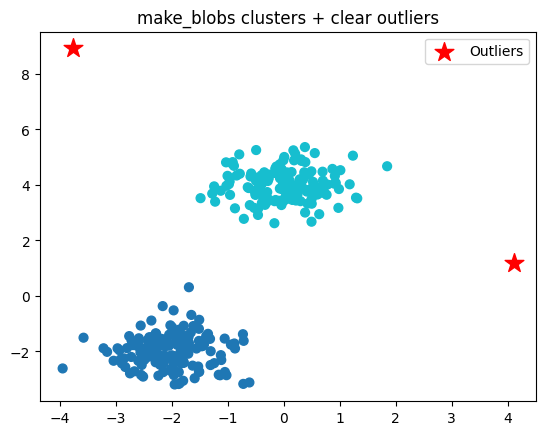

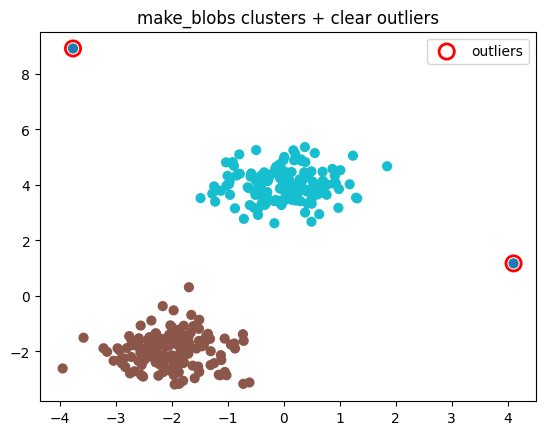

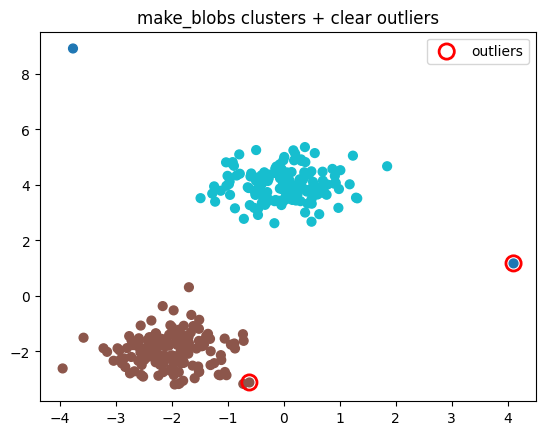

/tmp/ipython-input-1011071791.py:158: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(X_full[:,0], X_full[:,1], c='red', cmap="coolwarm", s=20)


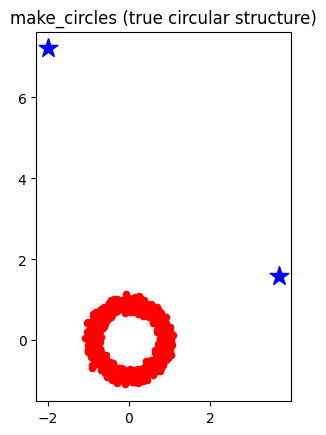

/tmp/ipython-input-1011071791.py:199: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(X_full[:,0], X_full[:,1], c='blue', cmap="coolwarm", s=20)


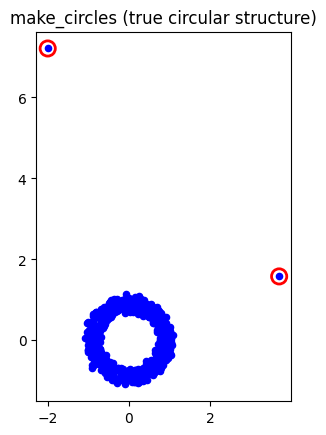

/tmp/ipython-input-1011071791.py:242: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(X_full[:,0], X_full[:,1], c='blue', cmap="coolwarm", s=20)


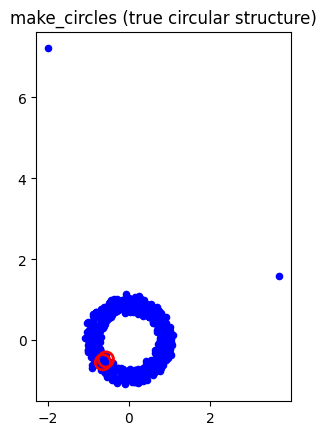

/tmp/ipython-input-1011071791.py:275: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


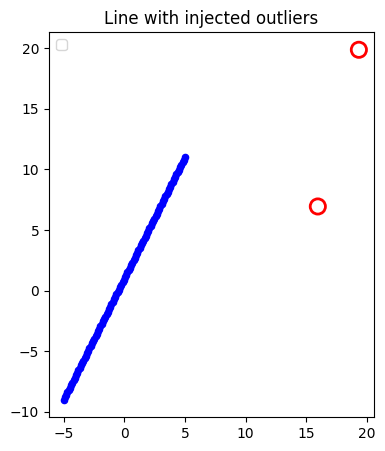

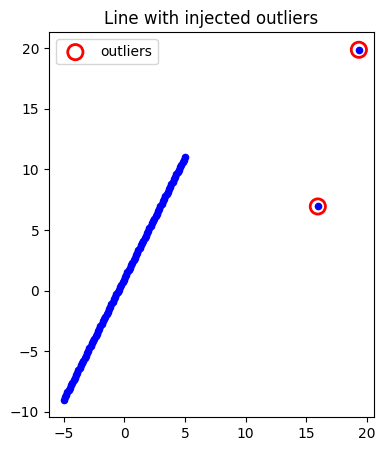

/tmp/ipython-input-1011071791.py:361: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


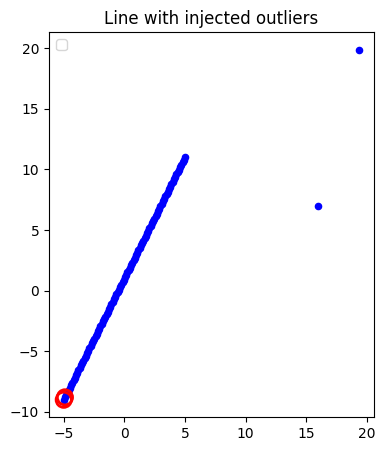

Cosine distance matrix:
 [[0.    0.    1.038]
 [0.    0.    1.038]
 [1.038 1.038 0.   ]]

Euclidean distance matrix:
 [[  0.     91.421  33.023]
 [ 91.421   0.    117.424]
 [ 33.023 117.424   0.   ]]
Cosine distance:
 [[0.         0.         0.73273876]
 [0.         0.         0.73273876]
 [0.73273876 0.73273876 0.        ]]

Euclidean distance:
 [[ 0.         33.67491648  3.60555128]
 [33.67491648  0.         37.16180835]
 [ 3.60555128 37.16180835  0.        ]]
Top 5 outliers by mean distance: [ 82 352 180 212 461]


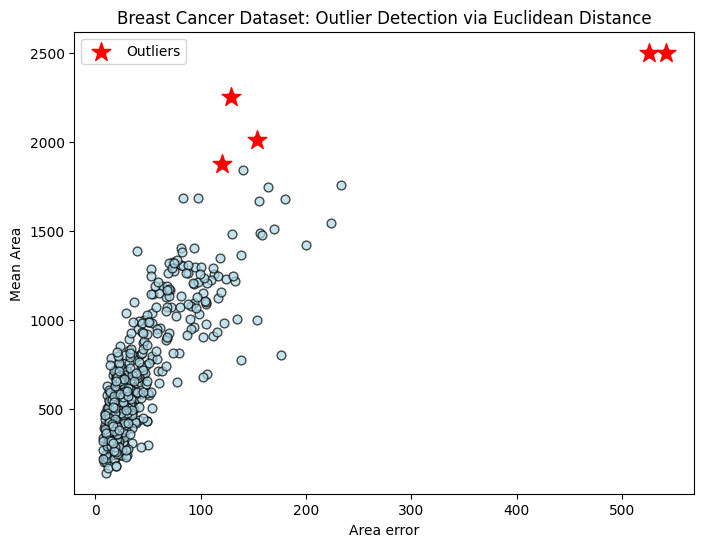

Top 5 outliers by mean distance: [152 258 212 461 417]


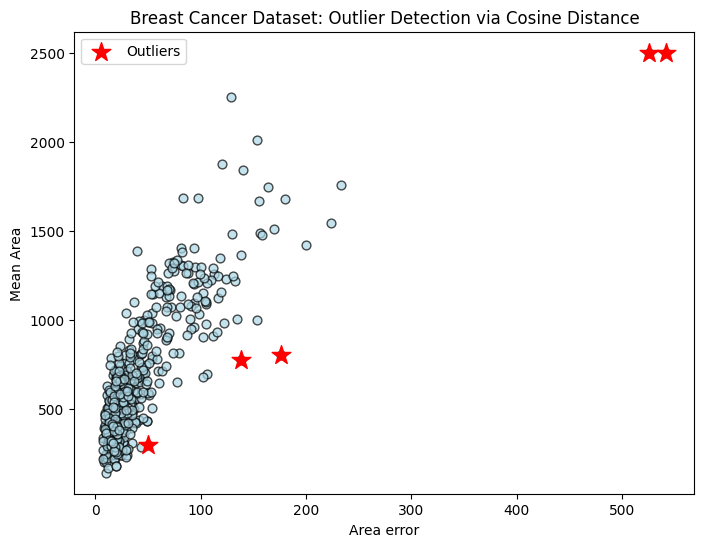

Distance matrix shape: (50, 50)


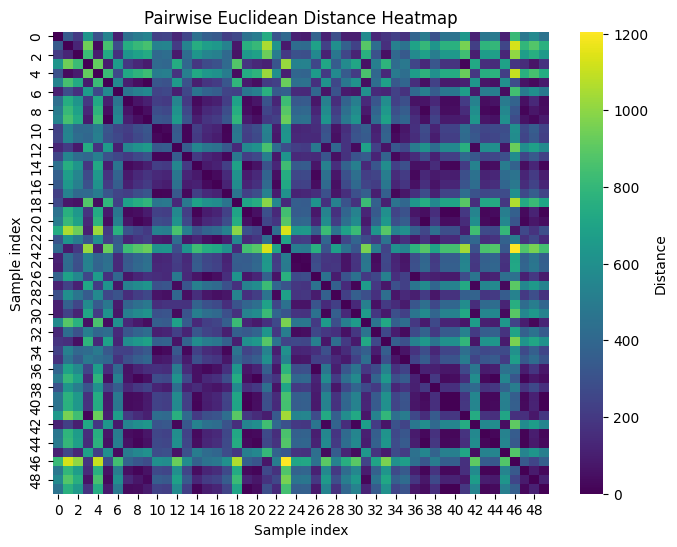

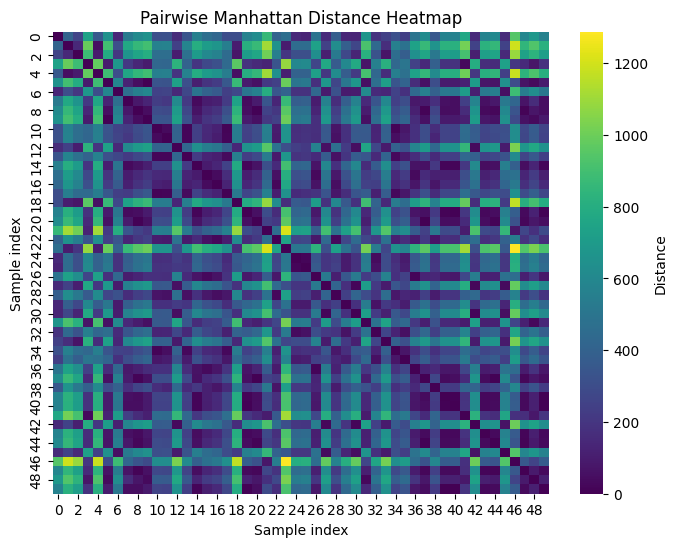

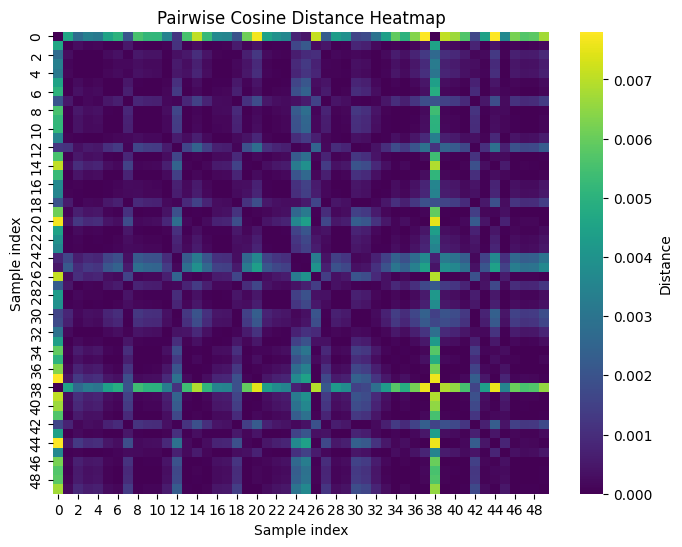

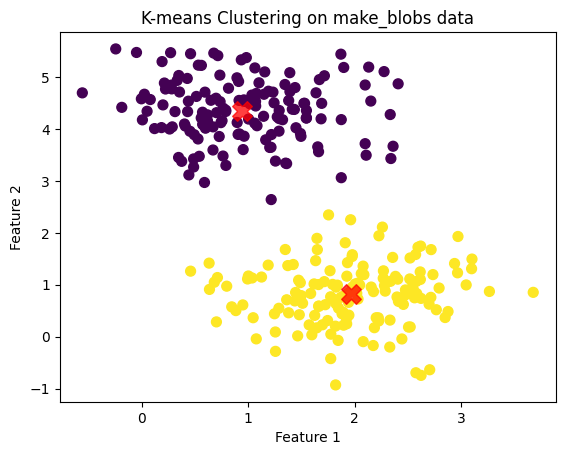

In [ ]:
import numpy as np

def euclidean(a, b):
    return np.sqrt(np.sum((a - b) ** 2))

def manhattan(a, b):
    return np.sum(np.abs(a - b))

def minkowski(a, b, p=3):
    return np.sum(np.abs(a - b) ** p) ** (1/p)

# Input pair 1
a1 = np.array([1, 2])
b1 = np.array([4, 6])

# Input pair 2
a2 = np.array([2, 3, 5])
b2 = np.array([2, 3, 5])

print("=== Input pair 1: a =", a1, " b =", b1, " ===")
print("Euclidean distance:", euclidean(a1, b1))
print("Manhattan distance:", manhattan(a1, b1))
print("Minkowski distance (p=3):", minkowski(a1, b1, p=3))

print("\n=== Input pair 2: a =", a2, " b =", b2, " ===")
print("Euclidean distance:", euclidean(a2, b2))
print("Manhattan distance:", manhattan(a2, b2))
print("Minkowski distance (p=3):", minkowski(a2, b2, p=3))

from sklearn.datasets import make_blobs
from sklearn.metrics import pairwise_distances

# --- 1) Make clustered data ---
X, y = make_blobs(n_samples=300,
                  centers=[(-2, -2), (0, 4)],
                  cluster_std=0.6,
                  random_state=42)

# --- 2) Inject outliers ---
n_outliers = 2
rng = np.random.RandomState(42)

# choose a wide box far outside clusters
X_outliers = rng.uniform(low=-12, high=10, size=(n_outliers, 2))


# combine
#X_full = np.vstack([X, X_outliers])
#y_full = np.hstack([y, [-1]*n_outliers])  # mark outliers as -1


# --- 3) Plot ---
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="tab10", s=40)
plt.scatter(X_outliers[:,0], X_outliers[:,1],
            c="red", marker="*", s=200, label="Outliers")
#plt.scatter(X_outliers[:, 0], X_outliers[:, 1], facecolors="none", edgecolors="red", s=120, linewidths=2, label="outliers")
plt.legend()
plt.title("make_blobs clusters + clear outliers")
plt.show()

from sklearn.metrics import pairwise_distances

# --- 1) Make clustered data ---
X, y = make_blobs(n_samples=300,
                  centers=[(-2, -2), (0, 4)],
                  cluster_std=0.6,
                  random_state=42)

# --- 2) Inject outliers ---
n_outliers = 2
rng = np.random.RandomState(42)

# choose a wide box far outside clusters
X_outliers = rng.uniform(low=-12, high=10, size=(n_outliers, 2))


# combine
X_full = np.vstack([X, X_outliers])
y_full = np.hstack([y, [-1]*n_outliers])  # mark outliers as -1

# TO-DO
# --- Compute pairwise Euclidean distances ---
D = pairwise_distances(X_full, metric="euclidean")

# Distance profile: average distance to all other points
mean_dist = D.mean(axis=1)

# Identify potential outliers (top-2 by average distance)
outlier_indices = np.argsort(mean_dist)[-2:][::-1]

# --- 3) Plot ---
plt.scatter(X_full[:, 0], X_full[:, 1], c=y_full, cmap="tab10", s=40)
plt.scatter(X_full[outlier_indices,0], X_full[outlier_indices,1],
            facecolors="none", edgecolors="red",
            s=120, linewidths=2, label="outliers")

plt.legend()
plt.title("make_blobs clusters + clear outliers")
plt.show()

# --- 1) Make clustered data ---
X, y = make_blobs(n_samples=300,
                  centers=[(-2, -2), (0, 4)],
                  cluster_std=0.6,
                  random_state=42)

# --- 2) Inject outliers ---
n_outliers = 2
rng = np.random.RandomState(42)

# choose a wide box far outside clusters
X_outliers = rng.uniform(low=-12, high=10, size=(n_outliers, 2))


# combine
X_full = np.vstack([X, X_outliers])
y_full = np.hstack([y, [-1]*n_outliers])  # mark outliers as -1

# TO-DO
# --- Compute pairwise Cosine distances ---
D = pairwise_distances(X_full, metric="cosine")

# TO-DO
# Distance profile: average distance to all other points
mean_dist = D.mean(axis=1)

# TO-DO
# Identify potential outliers (top-2 by average distance)
outlier_indices = np.argsort(mean_dist)[-2:]

# --- 3) Plot ---
plt.scatter(X_full[:, 0], X_full[:, 1], c=y_full, cmap="tab10", s=40)
#plt.scatter(X_full[outlier_indices,0], X_full[outlier_indices,1],
#            c="red", marker="*", s=200, label="Outliers")

plt.scatter(X_full[outlier_indices,0], X_full[outlier_indices,1],
            facecolors="none", edgecolors="red",
            s=120, linewidths=2, label="outliers")
plt.legend()
plt.title("make_blobs clusters + clear outliers")
plt.show()

from sklearn.datasets import make_circles

X, y = make_circles(n_samples=500, factor=0.8, noise=0.05, random_state=42)

# --- 2) Inject outliers ---
n_outliers = 2
rng = np.random.RandomState(42)

# choose a wide box far outside clusters
X_outliers = rng.uniform(low=-8, high=8, size=(n_outliers, 2))

# combine
X_full = np.vstack([X, X_outliers])
y_full = np.hstack([y, [-1]*n_outliers])  # mark outliers as -1

plt.scatter(X_full[:,0], X_full[:,1], c='red', cmap="coolwarm", s=20)

plt.scatter(X_outliers[:,0], X_outliers[:,1],
            c="blue", marker="*", s=200, label="Outliers")

plt.gca().set_aspect("equal")
plt.title("make_circles (true circular structure)")
plt.show()

from sklearn.datasets import make_circles
from sklearn.metrics import pairwise_distances

X, y = make_circles(n_samples=500, factor=0.8, noise=0.05, random_state=42)




# --- 2) Inject outliers ---
n_outliers = 2
rng = np.random.RandomState(42)

# choose a wide box far outside clusters
X_outliers = rng.uniform(low=-8, high=8, size=(n_outliers, 2))

# combine
X_full = np.vstack([X, X_outliers])
y_full = np.hstack([y, [-1]*n_outliers])  # mark outliers as -1

# TO-DO
# --- Compute pairwise Euclidean distances ---
D = pairwise_distances(X_full, metric="euclidean")

# TO-DO
# Distance profile: average distance to all other points
np.fill_diagonal(D, np.nan)
mean_dist = np.nanmean(D, axis=1)

# TO-DO
# Identify potential outliers (top-2 by average distance)
outlier_indices = np.argsort(mean_dist)[-n_outliers:]

plt.scatter(X_full[:,0], X_full[:,1], c='blue', cmap="coolwarm", s=20)

#plt.scatter(X_full[outlier_indices,0], X_full[outlier_indices,1],
#            c="blue", marker="*", s=200, label="Outliers")

plt.scatter(X_full[outlier_indices,0], X_full[outlier_indices,1],
            facecolors="none", edgecolors="red",
            s=120, linewidths=2, label="outliers")


plt.gca().set_aspect("equal")
plt.title("make_circles (true circular structure)")
plt.show()

X, y = make_circles(n_samples=500, factor=0.8, noise=0.05, random_state=42)




# --- 2) Inject outliers ---
n_outliers = 2
rng = np.random.RandomState(42)

# choose a wide box far outside clusters
X_outliers = rng.uniform(low=-8, high=8, size=(n_outliers, 2))

# combine
X_full = np.vstack([X, X_outliers])
y_full = np.hstack([y, [-1]*n_outliers])  # mark outliers as -1

# TO-DO
# --- Compute pairwise Cosine distances ---
D = pairwise_distances(X_full, metric="cosine")

# TO-DO
# Distance profile: average distance to all other points
np.fill_diagonal(D, np.nan)
mean_dist = np.nanmean(D, axis=1)

# TO-DO
# Identify potential outliers (top-2 by average distance)
outlier_indices = np.argsort(mean_dist)[-n_outliers:]

plt.scatter(X_full[:,0], X_full[:,1], c='blue', cmap="coolwarm", s=20)

plt.scatter(X_full[outlier_indices,0], X_full[outlier_indices,1],
            facecolors="none", edgecolors="red",
            s=120, linewidths=2, label="outliers")

plt.gca().set_aspect("equal")
plt.title("make_circles (true circular structure)")
plt.show()

import numpy as np
import matplotlib.pyplot as plt

# --- 1. Points along a line y = 2x + 1 ---
n_points = 100
xs = np.linspace(-5, 5, n_points)
ys = 2 * xs + 1
line_points = np.column_stack((xs, ys))

# --- 2. Add outliers ---
n_outliers = 2
rng = np.random.default_rng(42)
outliers = rng.uniform(low=[-15, -15], high=[25, 35], size=(n_outliers, 2))

# --- 3. Combine ---
X = np.vstack([line_points, outliers])
labels = np.array([0]*len(line_points) + [-1]*len(outliers))  # mark outliers as -1

# --- 4. Visualize ---
plt.figure(figsize=(7,5))
plt.scatter(line_points[:,0], line_points[:,1], c="blue", s=20)
plt.scatter(outliers[:,0], outliers[:,1], facecolors="none", edgecolors="red",
            s=120, linewidths=2)
plt.legend()
plt.gca().set_aspect("equal")
plt.title("Line with injected outliers")
plt.show()

import numpy as np
import matplotlib.pyplot as plt

# --- 1. Points along a line y = 2x + 1 ---
n_points = 100
xs = np.linspace(-5, 5, n_points)
ys = 2 * xs + 1
line_points = np.column_stack((xs, ys))

# --- 2. Add outliers ---
n_outliers = 2
rng = np.random.default_rng(42)
outliers = rng.uniform(low=[-15, -15], high=[25, 35], size=(n_outliers, 2))

# --- 3. Combine ---
X = np.vstack([line_points, outliers])
labels = np.array([0]*len(line_points) + [-1]*len(outliers))  # mark outliers as -1

# --- Compute pairwise Euclidean distances ---
diff = X[:, None, :] - X[None, :, :]
D = np.sqrt(np.sum(diff**2, axis=2))

# --- Distance profile: average distance to all other points (ignore self-distances)
np.fill_diagonal(D, np.nan)
mean_dist = np.nanmean(D, axis=1)

# --- Identify potential outliers (top-2 by average distance)
outlier_indices = np.argsort(mean_dist)[-n_outliers:]

# --- 4. Visualize ---
plt.figure(figsize=(7,5))
plt.scatter(X[:,0], X[:,1], c="blue", s=20)
plt.scatter(X[outlier_indices,0], X[outlier_indices,1],
            facecolors="none", edgecolors="red",
            s=120, linewidths=2, label="outliers")
plt.legend()
plt.gca().set_aspect("equal")
plt.title("Line with injected outliers")
plt.show()

import numpy as np
import matplotlib.pyplot as plt

# --- 1. Points along a line y = 2x + 1 ---
n_points = 100
xs = np.linspace(-5, 5, n_points)
ys = 2 * xs + 1
line_points = np.column_stack((xs, ys))

# --- 2. Add outliers ---
n_outliers = 2
rng = np.random.default_rng(42)
outliers = rng.uniform(low=[-15, -15], high=[25, 35], size=(n_outliers, 2))

# --- 3. Combine ---
X = np.vstack([line_points, outliers])
labels = np.array([0]*len(line_points) + [-1]*len(outliers))  # mark outliers as -1

# TO-DO
# --- Compute pairwise Cosine distances ---
# Cosine similarity S = (X X^T) / (||x_i|| * ||x_j||)
# Cosine distance D = 1 - S
norms = np.linalg.norm(X, axis=1, keepdims=True)          # (N,1)
# add tiny epsilon to avoid divide-by-zero for any zero-length vector
eps = 1e-12
S = (X @ X.T) / ((norms + eps) @ (norms.T + eps))
D = 1.0 - S

# TO-DO
# Distance profile: average distance to all other points
mean_dist = (D.sum(axis=1) - np.diag(D)) / (D.shape[1] - 1)

# TO-DO
# Identify potential outliers (top-2 by average distance)
outlier_indices = np.argsort(mean_dist)[-n_outliers:]

# --- 4. Visualize ---
plt.figure(figsize=(7,5))
plt.scatter(X[:,0], X[:,1], c="blue", s=20)
plt.scatter(X[outlier_indices,0], X[outlier_indices,1], facecolors="none", edgecolors="red",
            s=120, linewidths=2)
plt.legend()
plt.gca().set_aspect("equal")
plt.title("Line with injected outliers")
plt.show()

import numpy as np
from sklearn.metrics.pairwise import cosine_distances, euclidean_distances

rng = np.random.default_rng(0)

# Simulate 512-d image embeddings
# Image A: a "reference image"
img_A = rng.normal(size=(1, 512))

# Image B: same class (embedding points in nearly the same direction, scaled)
img_B = img_A * 5.0 + rng.normal(scale=0.01, size=(1, 512))

# Image C: different class (independent random vector)
img_C = rng.normal(size=(1, 512))

X = np.vstack([img_A, img_B, img_C])

# Compute cosine vs Euclidean distances
cos_dist = cosine_distances(X)
euc_dist = euclidean_distances(X)

print("Cosine distance matrix:\n", np.round(cos_dist, 3))
print("\nEuclidean distance matrix:\n", np.round(euc_dist, 3))

import numpy as np
from sklearn.metrics.pairwise import cosine_distances, euclidean_distances

# Imagine TF–IDF style vectors for documents
doc_short = np.array([[1, 2, 3]])        # small vector
doc_long  = np.array([[10, 20, 30]])     # same proportions, larger magnitude

# Add a different document
doc_diff  = np.array([[1, 0, 0]])        # very different direction

X = np.vstack([doc_short, doc_long, doc_diff])

# --- Compute distances ---
cos_dist = cosine_distances(X)
euc_dist = euclidean_distances(X)

print("Cosine distance:\n", cos_dist)
print("\nEuclidean distance:\n", euc_dist)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import pairwise_distances

# --- Load dataset ---
cancer = load_breast_cancer()
X = pd.DataFrame(cancer.data, columns=cancer.feature_names)

cancer.feature_names

from sklearn.metrics import pairwise_distances
import numpy as np
import matplotlib.pyplot as plt

# Use only two features: mean radius and mean area
X2 = X[['area error', 'mean area']].values

# --- Compute pairwise Euclidean distances ---
D = pairwise_distances(X2, metric="euclidean")

# --- Distance profile: average distance to all other points
# (ignore self-distances, which are 0 on the diagonal)
mean_dist = (D.sum(axis=1)) / (D.shape[1] - 1)

# --- Identify potential outliers (top-5 by average distance)
outlier_indices = np.argsort(mean_dist)[-5:]
print("Top 5 outliers by mean distance:", outlier_indices)

# --- Plot ---
plt.figure(figsize=(8,6))
plt.scatter(X2[:,0], X2[:,1], c="lightblue", s=40, edgecolor="k", alpha=0.7)
plt.scatter(X2[outlier_indices,0], X2[outlier_indices,1],
            c="red", marker="*", s=200, label="Outliers")
plt.xlabel("Area error")
plt.ylabel("Mean Area")
plt.title("Breast Cancer Dataset: Outlier Detection via Euclidean Distance")
plt.legend()
plt.show()

# --- Compute pairwise Cosine distances ---
D = pairwise_distances(X2, metric="cosine")

# --- Distance profile: average distance to all other points
# (ignore self-distances, which are 0 on the diagonal)
mean_dist = (D.sum(axis=1)) / (D.shape[1] - 1)

# --- Identify potential outliers (top-5 by average distance)
outlier_indices = np.argsort(mean_dist)[-5:]
print("Top 5 outliers by mean distance:", outlier_indices)

# --- Plot ---
plt.figure(figsize=(8,6))
plt.scatter(X2[:,0], X2[:,1], c="lightblue", s=40, edgecolor="k", alpha=0.7)
plt.scatter(X2[outlier_indices,0], X2[outlier_indices,1],
            c="red", marker="*", s=200, label="Outliers")
plt.xlabel("Area error")
plt.ylabel("Mean Area")
plt.title("Breast Cancer Dataset: Outlier Detection via Cosine Distance")
plt.legend()
plt.show()

import seaborn as sns

# Select just two features
X2 = X[['area error', 'mean area']].values
X2 = X2[:50, :]   # take a smaller subset for clearer heatmap

# --- Compute pairwise distances ---
D_euclidean = pairwise_distances(X2, metric="euclidean")
D_manhattan = pairwise_distances(X2, metric="manhattan")
D_cosine    = pairwise_distances(X2, metric="cosine")

print("Distance matrix shape:", D_euclidean.shape)  # (50, 50)

# --- Heatmap plotting function ---
def plot_heatmap(D, title):
    plt.figure(figsize=(8,6))
    sns.heatmap(D, cmap="viridis", cbar_kws={'label': 'Distance'})
    plt.title(title)
    plt.xlabel("Sample index")
    plt.ylabel("Sample index")
    plt.show()

# Plot heatmaps for each metric
plot_heatmap(D_euclidean, "Pairwise Euclidean Distance Heatmap")
plot_heatmap(D_manhattan, "Pairwise Manhattan Distance Heatmap")
plot_heatmap(D_cosine,    "Pairwise Cosine Distance Heatmap")

from sklearn.datasets import make_blobs
# Generate data

X, y = make_blobs(n_samples=300, centers=2, cluster_std=0.60, random_state=0)

from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=2, random_state=0, n_init='auto') # n_init='auto' for modern versions
kmeans.fit(X)
labels = kmeans.predict(X)

plt.scatter(X[:, 0], X[:, 1], c=labels, s=50, cmap='viridis')
centers = kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.75, marker='X')
plt.title('K-means Clustering on make_blobs data')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.show()

